In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
accepted_cols = ['loan_amnt', 'fico_range_low', 'dti', 'emp_length', 'addr_state']
rejected_cols = ['Amount Requested', 'Risk_Score', 'Debt-To-Income Ratio', 'Employment Length', 'State']
accepted_df = pd.read_csv("accepted.csv", usecols=accepted_cols, nrows=25000)
rejected_df = pd.read_csv("rejected.csv", usecols=rejected_cols, nrows=25000)
print("Accepted Sample Shape:", accepted_df.shape)
print("Rejected Sample Shape:", rejected_df.shape)

Accepted Sample Shape: (25000, 5)
Rejected Sample Shape: (25000, 5)


In [3]:
accepted_df['approval_status'] = 1
rejected_df['approval_status'] = 0
rejected_df = rejected_df.rename(columns={
    'Amount Requested': 'loan_amnt',
    'Risk_Score': 'fico_range_low',
    'Debt-To-Income Ratio': 'dti',
    'Employment Length': 'emp_length',
    'State': 'addr_state'
})
df_model1 = pd.concat([
    accepted_df.dropna(subset=['loan_amnt']).sample(n=10000, random_state=42),
    rejected_df.dropna(subset=['loan_amnt']).sample(n=10000, random_state=42)
], ignore_index=True)
df_model1 = df_model1.sample(frac=1.0, random_state=42).reset_index(drop=True)
print("Combined Dataset Shape:", df_model1.shape)
df_model1.head()

Combined Dataset Shape: (20000, 6)


,loan_amnt,emp_length,addr_state,dti,fico_range_low,approval_status
0,10000.0,1 year,GA,0%,0.0,0
1,20000.0,10+ years,NY,16.95,675.0,1
2,11900.0,< 1 year,CA,20.82,755.0,1
3,35000.0,3 years,NY,6.59,735.0,1
4,7500.0,< 1 year,FL,62400%,624.0,0


In [4]:
print("Shape of dataset:", df_model1.shape)
print("\nColumn Names:")
print(df_model1.columns)
print("\nDataset Info:")
df_model1.info()
print("\nTarget Class Distribution (1 = Approved, 0 = Rejected):")
print(df_model1['approval_status'].value_counts())

Shape of dataset: (20000, 6)

Column Names:
Index(['loan_amnt', 'emp_length', 'addr_state', 'dti', 'fico_range_low',
       'approval_status'],
      dtype='str')

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   loan_amnt        20000 non-null  float64
 1   emp_length       19410 non-null  str    
 2   addr_state       19991 non-null  str    
 3   dti              20000 non-null  object 
 4   fico_range_low   19244 non-null  float64
 5   approval_status  20000 non-null  int64  
dtypes: float64(2), int64(1), object(1), str(2)
memory usage: 937.6+ KB

Target Class Distribution (1 = Approved, 0 = Rejected):
approval_status
0    10000
1    10000
Name: count, dtype: int64


In [5]:
df_model1['dti'] = df_model1['dti'].astype(str).str.rstrip('%')
df_model1['dti'] = pd.to_numeric(df_model1['dti'], errors='coerce')
def clean_emp_length(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip()
    if '<' in val:
        return 0.5
    if '10+' in val:
        return 10.0
    for word in val.split():
        if word.isdigit():
            return float(word)
    return np.nan
df_model1['emp_length'] = df_model1['emp_length'].apply(clean_emp_length)
print(df_model1.dtypes)
df_model1.head()

loan_amnt          float64
emp_length         float64
addr_state             str
dti                float64
fico_range_low     float64
approval_status      int64
dtype: object


,loan_amnt,emp_length,addr_state,dti,fico_range_low,approval_status
0,10000.0,1.0,GA,0.00,0.0,0
1,20000.0,10.0,NY,16.95,675.0,1
2,11900.0,0.5,CA,20.82,755.0,1
3,35000.0,3.0,NY,6.59,735.0,1
4,7500.0,0.5,FL,62400.00,624.0,0


In [6]:
print(df_model1.isnull().sum())
num_cols_m1 = ['loan_amnt', 'fico_range_low', 'dti', 'emp_length']
for col in num_cols_m1:
    df_model1[col] = df_model1[col].fillna(df_model1[col].median())
df_model1['addr_state'] = df_model1['addr_state'].fillna(df_model1['addr_state'].mode()[0])
print(df_model1.isnull().sum())
print("\nDuplicate rows found:", df_model1.duplicated().sum())
df_model1 = df_model1.drop_duplicates().reset_index(drop=True)
df_model1['dti'] = df_model1['dti'].clip(lower=0, upper=df_model1['dti'].quantile(0.99))
df_model1['fico_range_low'] = df_model1['fico_range_low'].clip(lower=300, upper=850)
print("Cleaned Model 1 Shape:", df_model1.shape)
df_model1.describe()

loan_amnt            0
emp_length         590
addr_state           9
dti                  0
fico_range_low     756
approval_status      0
dtype: int64
loan_amnt          0
emp_length         0
addr_state         0
dti                0
fico_range_low     0
approval_status    0
dtype: int64

Duplicate rows found: 88
Cleaned Model 1 Shape: (19912, 6)


,loan_amnt,emp_length,dti,fico_range_low,approval_status
count,19912.000000,19912.000000,19912.000000,19912.000000,19912.000000
mean,11751.205490,4.801728,21.951766,641.641874,0.502210
std,8540.027499,3.709829,30.204688,93.310856,0.500008
min,500.000000,0.500000,0.000000,300.000000,0.000000
25%,5000.000000,1.000000,8.740000,609.000000,0.000000
50%,10000.000000,4.000000,17.295000,670.000000,1.000000
75%,17000.000000,9.000000,26.350000,695.000000,1.000000
max,35000.000000,10.000000,258.722600,845.000000,1.000000


C:\Users\GOUTHAM\AppData\Local\Temp\ipykernel_10176\1793789181.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='approval_status', data=df_model1, palette='Set2')
C:\Users\GOUTHAM\AppData\Local\Temp\ipykernel_10176\1793789181.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='approval_status', y='fico_range_low', data=df_model1, palette='Set2')
C:\Users\GOUTHAM\AppData\Local\Temp\ipykernel_10176\1793789181.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='approval_status', y='dti', data=df_model1, palette='Set2')


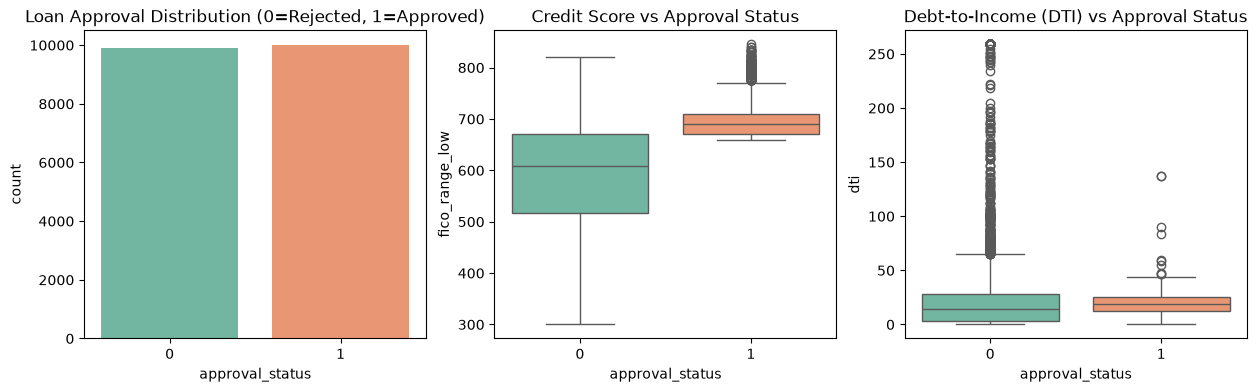

In [7]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
sns.countplot(x='approval_status', data=df_model1, palette='Set2')
plt.title('Loan Approval Distribution (0=Rejected, 1=Approved)')
plt.subplot(1, 3, 2)
sns.boxplot(x='approval_status', y='fico_range_low', data=df_model1, palette='Set2')
plt.title('Credit Score vs Approval Status')
plt.subplot(1, 3, 3)
sns.boxplot(x='approval_status', y='dti', data=df_model1, palette='Set2')
plt.title('Debt-to-Income (DTI) vs Approval Status')
plt.show()

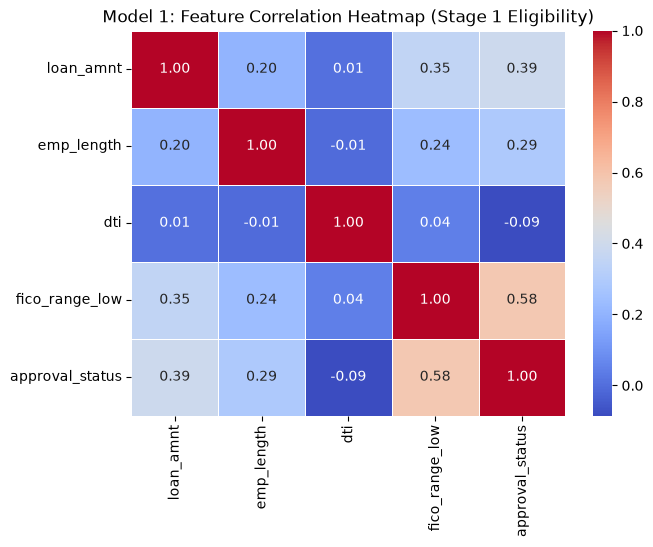


Average Feature Values by Historical Approval Status:
                 loan_amnt  fico_range_low    dti  emp_length
approval_status                                              
0                  8397.66          587.52  24.53        3.72
1                 15075.24          695.29  19.39        5.88


In [8]:
plt.figure(figsize=(7, 5))
corr_m1 = df_model1.corr(numeric_only=True)
sns.heatmap(corr_m1, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Model 1: Feature Correlation Heatmap (Stage 1 Eligibility)')
plt.show()
print("\nAverage Feature Values by Historical Approval Status:")
print(df_model1.groupby('approval_status')[['loan_amnt', 'fico_range_low', 'dti', 'emp_length']].mean().round(2))

In [9]:
df_model1['dti_to_fico'] = df_model1['dti'] / (df_model1['fico_range_low'] + 1)
top_states = df_model1['addr_state'].value_counts().nlargest(10).index
df_model1['addr_state_grouped'] = df_model1['addr_state'].where(
    df_model1['addr_state'].isin(top_states), 'OTHER'
)
X_m1 = df_model1.drop(columns=['approval_status', 'addr_state'])
y_m1 = df_model1['approval_status']
X_m1 = pd.get_dummies(
    X_m1,
    columns=['addr_state_grouped'],
    drop_first=True
)
print("X_m1 shape after One-Hot Encoding:", X_m1.shape)
print("y_m1 shape:", y_m1.shape)
print("\nEncoded Feature Columns:")
print(X_m1.columns.tolist())
X_m1.head()

X_m1 shape after One-Hot Encoding: (19912, 15)
y_m1 shape: (19912,)

Encoded Feature Columns:
['loan_amnt', 'emp_length', 'dti', 'fico_range_low', 'dti_to_fico', 'addr_state_grouped_FL', 'addr_state_grouped_GA', 'addr_state_grouped_IL', 'addr_state_grouped_NJ', 'addr_state_grouped_NY', 'addr_state_grouped_OH', 'addr_state_grouped_OTHER', 'addr_state_grouped_PA', 'addr_state_grouped_TX', 'addr_state_grouped_VA']


,loan_amnt,emp_length,dti,fico_range_low,dti_to_fico,addr_state_grouped_FL,addr_state_grouped_GA,addr_state_grouped_IL,addr_state_grouped_NJ,addr_state_grouped_NY,addr_state_grouped_OH,addr_state_grouped_OTHER,addr_state_grouped_PA,addr_state_grouped_TX,addr_state_grouped_VA
0,10000.0,1.0,0.0000,300.0,0.000000,False,True,False,False,False,False,False,False,False,False
1,20000.0,10.0,16.9500,675.0,0.025074,False,False,False,False,True,False,False,False,False,False
2,11900.0,0.5,20.8200,755.0,0.027540,False,False,False,False,False,False,False,False,False,False
3,35000.0,3.0,6.5900,735.0,0.008954,False,False,False,False,True,False,False,False,False,False
4,7500.0,0.5,258.7226,624.0,0.413956,True,False,False,False,False,False,False,False,False,False


In [10]:
X_train_m1, X_test_m1, y_train_m1, y_test_m1 = train_test_split(
    X_m1,
    y_m1,
    test_size=0.20,
    random_state=42,
    stratify=y_m1
)

print("Training data shape:", X_train_m1.shape)
print("Testing data shape :", X_test_m1.shape)
scaler_m1 = StandardScaler()
X_train_m1_scaled = scaler_m1.fit_transform(X_train_m1)
X_test_m1_scaled = scaler_m1.transform(X_test_m1)

Training data shape: (15929, 15)
Testing data shape : (3983, 15)


In [11]:
log_reg_m1 = LogisticRegression(max_iter=1000, random_state=42)
knn_m1 = KNeighborsClassifier(n_neighbors=5)
nb_m1 = GaussianNB()
svm_rbf_m1 = SVC(kernel='rbf', C=1, gamma='scale', probability=True, random_state=42)
dt_m1 = DecisionTreeClassifier(criterion='gini', random_state=42)
rf_m1 = RandomForestClassifier(n_estimators=100, random_state=42)

In [12]:
log_reg_m1.fit(X_train_m1_scaled, y_train_m1)
knn_m1.fit(X_train_m1_scaled, y_train_m1)
nb_m1.fit(X_train_m1_scaled, y_train_m1)
svm_rbf_m1.fit(X_train_m1_scaled, y_train_m1)
dt_m1.fit(X_train_m1_scaled, y_train_m1)
rf_m1.fit(X_train_m1_scaled, y_train_m1)

C:\Users\GOUTHAM\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [13]:
from sklearn.metrics import roc_auc_score, roc_curve
y_pred_m1 = log_reg_m1.predict(X_test_m1_scaled)
y_proba_m1 = log_reg_m1.predict_proba(X_test_m1_scaled)[:, 1]
print("Model 1 (Logistic Regression) Evaluation:")
print("Accuracy:", accuracy_score(y_test_m1, y_pred_m1))
print("Precision:", precision_score(y_test_m1, y_pred_m1))
print("Recall:", recall_score(y_test_m1, y_pred_m1))
print("F1 Score:", f1_score(y_test_m1, y_pred_m1))
print("ROC-AUC Score:", roc_auc_score(y_test_m1, y_proba_m1))
print("\nClassification Report:\n", classification_report(y_test_m1, y_pred_m1))
cm_m1 = confusion_matrix(y_test_m1, y_pred_m1)
tn, fp, fn, tp = cm_m1.ravel()
print(f"True Negatives (Correctly Rejected): {tn}")
print(f"False Positives (False Approvals / Risk): {fp}")
print(f"False Negatives (False Rejections / Lost Business): {fn}")
print(f"True Positives (Correctly Approved): {tp}")
cost_false_approval = 5.0
cost_false_rejection = 1.0
total_underwriting_cost = (fp * cost_false_approval) + (fn * cost_false_rejection)
print(f"\nTotal Underwriting Policy Cost under Cost Matrix: {total_underwriting_cost:,.2f}")

Model 1 (Logistic Regression) Evaluation:
Accuracy: 0.8144614612101431
Precision: 0.7823555754590238
Recall: 0.8735
F1 Score: 0.8254193243562485
ROC-AUC Score: 0.8779316691880988

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.75      0.80      1983
           1       0.78      0.87      0.83      2000

    accuracy                           0.81      3983
   macro avg       0.82      0.81      0.81      3983
weighted avg       0.82      0.81      0.81      3983

True Negatives (Correctly Rejected): 1497
False Positives (False Approvals / Risk): 486
False Negatives (False Rejections / Lost Business): 253
True Positives (Correctly Approved): 1747

Total Underwriting Policy Cost under Cost Matrix: 2,683.00


In [14]:
from sklearn.model_selection import GridSearchCV
param_grid_m1 = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
grid_search_m1 = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_m1,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search_m1.fit(X_train_m1_scaled, y_train_m1)
print("Best Parameters for Stage 1:", grid_search_m1.best_params_)
print("Best Cross-Validation Score:", round(grid_search_m1.best_score_, 4))
best_rf_m1 = grid_search_m1.best_estimator_
y_pred_best_m1 = best_rf_m1.predict(X_test_m1_scaled)
print("Optimized Test Accuracy:", accuracy_score(y_test_m1, y_pred_best_m1))

Best Parameters for Stage 1: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation Score: 0.9178
Optimized Test Accuracy: 0.9136329399949786


In [17]:
import os
import joblib
from sklearn.exceptions import NotFittedError
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.validation import check_is_fitted

# Candidate Stage 1 models
candidates_m1 = {
    "Logistic_Regression": log_reg_m1,
    "KNN": knn_m1,
    "Naive_Bayes": nb_m1,
    "SVM_RBF": svm_rbf_m1,
    "Decision_Tree": dt_m1,
    "Random_Forest_Tuned": best_rf_m1 if "best_rf_m1" in locals() else rf_m1,
}

# Ensure every candidate is fitted before evaluation
for name, model in candidates_m1.items():
    try:
        check_is_fitted(model)
    except NotFittedError:
        print(f"Refitting unfitted Stage 1 model: {name}...")
        model.fit(X_train_m1_scaled, y_train_m1)

best_name_m1 = None
best_score_m1 = -1.0
active_model_m1 = None

# Evaluate all candidates and select the best model supporting predict_proba
for name, model in candidates_m1.items():
    preds = model.predict(X_test_m1_scaled)
    score = f1_score(y_test_m1, preds)
    acc = accuracy_score(y_test_m1, preds)
    has_proba = hasattr(model, "predict_proba")
    print(f"{name:22s} -> Test F1-Score: {score:.4f} | Accuracy: {acc:.4f} | Proba: {has_proba}")

    if has_proba and score > best_score_m1:
        best_score_m1 = score
        best_name_m1 = name
        active_model_m1 = model

if active_model_m1 is None:
    raise RuntimeError("No Stage 1 model supports predict_proba(). Check model configurations.")

print(f"\n>>> WINNING STAGE 1 MODEL SELECTED: {best_name_m1} (F1 = {best_score_m1:.4f})")

# Save winning model and Stage 1 artifacts
desktop_path = os.path.join(os.path.expanduser("~"), "Desktop")
models_dir = os.path.join(desktop_path, "project", "models")
os.makedirs(models_dir, exist_ok=True)

joblib.dump(active_model_m1, os.path.join(models_dir, "stage1_approval_model.joblib"))
joblib.dump(scaler_m1, os.path.join(models_dir, "stage1_scaler.joblib"))
joblib.dump(list(X_train_m1.columns), os.path.join(models_dir, "stage1_features.joblib"))
joblib.dump(
    {"X_test_scaled": X_test_m1_scaled, "y_test": y_test_m1.values},
    os.path.join(models_dir, "stage1_test_data.joblib"),
)

print(f"Stage 1 Artifacts saved successfully to: {models_dir}")

Logistic_Regression    -> Test F1-Score: 0.8254 | Accuracy: 0.8145 | Proba: True
KNN                    -> Test F1-Score: 0.8700 | Accuracy: 0.8592 | Proba: True
Naive_Bayes            -> Test F1-Score: 0.8498 | Accuracy: 0.8290 | Proba: True
SVM_RBF                -> Test F1-Score: 0.8766 | Accuracy: 0.8637 | Proba: True
Decision_Tree          -> Test F1-Score: 0.9062 | Accuracy: 0.9056 | Proba: True
Random_Forest_Tuned    -> Test F1-Score: 0.9184 | Accuracy: 0.9136 | Proba: True

>>> WINNING STAGE 1 MODEL SELECTED: Random_Forest_Tuned (F1 = 0.9184)
Stage 1 Artifacts saved successfully to: C:\Users\GOUTHAM\Desktop\project\models
